In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService
# from cobos.tokens import ibm_token, group_instance, group_instance2
from fradm.tokens import ibm_token, group_instance, group_instance2

channel = "ibm_quantum"
device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Simulator settings

In [3]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

simulator = AerSimulator.from_backend(backend)
# simulator = AerSimulator()

### imports

In [5]:
import numpy as np
from functools import partial
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

import z2chain.circs as circs
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from z2chain.clifford_circuits import near_clifford_circuits_set, load_circs
from z2chain.postselection import bias_corrected_get_recovered_samples_dicts
from z2chain.plotting import discrepancies_plot, x_t_separated_plot, x_t_plot
from z2chain.plotting import convert_jobs_to_site_gauge_matrix

from utils.sexec import execute_simulation_estimator_batch
from utils.hexec import get_backend_best_qubit_chain
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.postselection import initialize_postselection, get_recovered_postselected_samples_dict, measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str

/Users/fradm98/Desktop/qs-qh/src/z2chain/plotting.py:318: SyntaxWarning: invalid escape sequence '\&'
  plt.suptitle("Matter $\&$ Gauge sites of the transverse and longitudinal strings")


# Complete pipeline

1. logical circuits
2. take the logical circuit at time $t$ and create near-clifford circuits set $(n,N)$
3. execute with mps the near-clifford circuit and non-clifford circuit at time $t$
4. transpile, simulate, and postselect the near-clifford circuits and the non-clifford circuit at time $t$
5. with data regression correct the non-clifford circuit at time $t$

### utils function

In [92]:
def execute_mps_t(circ_t, logical_near_cliff_set):
    estimator_options = {
        "default_precision": 0
    }

    mps_simulator_options = {
        "method": "matrix_product_state",
        "matrix_product_state_max_bond_dimension": None,
        "matrix_product_state_truncation_threshold": 1e-16
    }

    observables_generating_funcs = [partial(local_pauli_z, qubit_ind=i) for i in range(2*L-1)]

    mps_jobs_non_cliff_t = execute_simulation_estimator_batch(mps_simulator_options, estimator_options, circ_t, observables_generating_funcs)
    mps_obs_non_cliff_t = convert_jobs_to_site_gauge_matrix(mps_jobs_non_cliff_t)

    mps_jobs_near_cliff_t = execute_simulation_estimator_batch(mps_simulator_options, estimator_options, logical_near_cliff_set, observables_generating_funcs)
    mps_obs_near_cliff_t = convert_jobs_to_site_gauge_matrix(mps_jobs_near_cliff_t)
    return mps_obs_non_cliff_t, mps_obs_near_cliff_t

def transpilation_settings(L, backend, simulator, optimization_level: int=3):
    # transpilation settings
    
    layout = get_backend_best_qubit_chain(backend, 2*L-1)
    trotter_pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=simulator, initial_layout=layout)
    return trotter_pm

def postselection_settings(L: int, x_basis: bool=False):
    # postselection settings

    observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
    postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

    postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

    postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
    to_remove_str = "I"*(2*L-3) + "ZZ"
    to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
    flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
    flipped_syndromes[to_remove_str_ind] = 1
    return postselection_ops, diagonal_observables, flipped_syndromes

def postselection_non_clifford(samples_dicts_non_cliff_t, postselection_ops, diagonal_observables, flipped_syndromes: np.ndarray=None, flip_threshold: float=None, confidence: float=0.7):
    postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_non_cliff_t, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
    # postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_non_cliff_t, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=bias_corrected_get_recovered_samples_dicts))
    sim_obs_non_cliff_t, sim_conf_non_cliff_t = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
    
    raw_obs_non_cliff_t = []
    raw_conf_non_cliff_t = []
    # postselected_samples_dicts = get_recovered_postselected_samples_dict(samples_dicts_non_cliff_t, postselection_ops, flip_threshold)
    # sim_obs_non_cliff_t, sim_conf_non_cliff_t = measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, confidence=confidence)    
    # raw_obs_non_cliff_t, raw_conf_non_cliff_t = measure_diagonal_observables(samples_dicts_non_cliff_t, diagonal_observables, confidence=confidence)

    sim_obs_non_cliff_t = np.array(sim_obs_non_cliff_t)
    sim_obs_non_cliff_t = (1 - sim_obs_non_cliff_t)/2
    sim_conf_non_cliff_t = np.array(sim_conf_non_cliff_t)
    # raw_obs_non_cliff_t = np.array(raw_obs_non_cliff_t)
    # raw_obs_non_cliff_t = (raw_obs_non_cliff_t - 1)/2
    # raw_conf_non_cliff_t = np.array(raw_conf_non_cliff_t)
    return sim_obs_non_cliff_t, sim_conf_non_cliff_t, raw_obs_non_cliff_t, raw_conf_non_cliff_t

def postselection_near_clifford(samples_dicts_near_cliff_t, postselection_ops, diagonal_observables, flipped_syndromes: np.ndarray=None, flip_threshold: float=None, confidence: float=0.7):
    sim_obs_near_cliff_t, sim_conf_near_cliff_t = [], []
    raw_obs_near_cliff_t, raw_conf_near_cliff_t = [], []
    for i in range(len(samples_dicts_near_cliff_t)):
        postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_near_cliff_t[i], postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
        # postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_near_cliff_t[i], postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=bias_corrected_get_recovered_samples_dicts))
        sim_observables, sim_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
        # postselected_samples_dicts = get_recovered_postselected_samples_dict(samples_dicts_near_cliff_t[i], postselection_ops, flip_threshold)
        # sim_observables, sim_observables_confidence = measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, confidence=confidence)
        # raw_observables, raw_observables_confidence = measure_diagonal_observables(samples_dicts_near_cliff_t[i], diagonal_observables, confidence=confidence)
        sim_obs_near_cliff_t.append(sim_observables)
        sim_conf_near_cliff_t.append(sim_observables_confidence)
        # raw_obs_near_cliff_t.append(raw_observables)
        # raw_conf_near_cliff_t.append(raw_observables_confidence)

    sim_obs_near_cliff_t = np.array(sim_obs_near_cliff_t)
    sim_obs_near_cliff_t = (1 - sim_obs_near_cliff_t)/2
    sim_conf_near_cliff_t = np.array(sim_conf_near_cliff_t)
    # raw_obs_near_cliff_t = np.array(raw_obs_near_cliff_t)
    # raw_obs_near_cliff_t = (raw_obs_near_cliff_t - 1)/2
    # raw_conf_near_cliff_t = np.array(raw_conf_near_cliff_t)
    return sim_obs_near_cliff_t, sim_conf_near_cliff_t, raw_obs_near_cliff_t, raw_conf_near_cliff_t

def transpile_simulate_postselect_non_clifford(circ_t, L, backend, simulator, shots_non_cliff: int=16000):
    # transpilation at time t
    trotter_pm = transpilation_settings(L, backend, simulator)
    circ_t.measure_all()
    physical_non_cliff_circ_t = trotter_pm.run(circ_t)

    # simulation at time t
    samples_dicts_non_cliff_t = simulator.run(physical_non_cliff_circ_t, shots=shots_non_cliff).result().get_counts()

    # postselection at time t
    postselection_ops, diagonal_observables, flipped_syndromes = postselection_settings(L)
    (sim_obs_non_cliff_t,
    sim_conf_non_cliff_t,
    raw_obs_non_cliff_t,
    raw_conf_non_cliff_t) = postselection_non_clifford(samples_dicts_non_cliff_t, postselection_ops, diagonal_observables)
    return sim_obs_non_cliff_t, sim_conf_non_cliff_t, raw_obs_non_cliff_t, raw_conf_non_cliff_t

def transpile_simulate_postselect_near_clifford(logical_near_cliff_set, L, backend, simulator, shots_near_cliff: int=8000):
    # transpilation at time t
    trotter_pm = transpilation_settings(L, backend, simulator)
    [nc_circ.measure_all() for nc_circ in logical_near_cliff_set]
    physical_circs = trotter_pm.run(logical_near_cliff_set)

    # simulation at time t
    samples_dicts_near_cliff_t = []
    for i in range(len(physical_circs)):
        print(f"\r -- simulation near clifford = {i}", end="")
        this_samples_dict = simulator.run(physical_circs[i], shots=shots_near_cliff).result().get_counts()
        samples_dicts_near_cliff_t.append(this_samples_dict)

    # postselection at time t
    postselection_ops, diagonal_observables, flipped_syndromes = postselection_settings(L)
    (sim_obs_near_cliff_t,
    sim_conf_near_cliff_t,
    raw_obs_near_cliff_t,
    raw_conf_near_cliff_t) = postselection_near_clifford(samples_dicts_near_cliff_t, postselection_ops, diagonal_observables)
    return sim_obs_near_cliff_t, sim_conf_near_cliff_t, raw_obs_near_cliff_t, raw_conf_near_cliff_t

def lin_regr(x,a,b):
    return a*x + b

def cdr_single_observable_t(exact_near_cliff_obs, noisy_near_cliff_obs, noisy_non_cliff_obs):
    y_train = exact_near_cliff_obs
    x_train = noisy_near_cliff_obs
    x_test = noisy_non_cliff_obs

    popt, cov = curve_fit(lin_regr, x_train, y_train)
    y_pred = lin_regr(x_test, *popt)
    err = np.sqrt(np.diag(cov))
    return y_pred, err

def cdr_observables_t(L, exact_near_cliff_obs, noisy_near_cliff_obs, noisy_non_cliff_obs, t: int = 0):

    y_regr_t = []
    y_regr_err_t = []
    for i in range(2*L-1):
        y_pred, y_err = cdr_single_observable_t(exact_near_cliff_obs[:,i], noisy_near_cliff_obs[:,i], noisy_non_cliff_obs[t,i])        
        y_regr_t.append(y_pred)
        y_regr_err_t.append(y_err)

    y_regr_t = np.array(y_regr_t)
    y_regr_err_t = np.array(y_regr_err_t)
    return y_regr_t, y_regr_err_t

def cdr_observables(L, exact_near_cliff_obs, noisy_near_cliff_obs, noisy_non_cliff_obs):

    y_regr = []
    y_regr_err = []
    for layer in range(len(noisy_non_cliff_obs)):
        y_regr_t, y_regr_err_t = cdr_observables_t(L, exact_near_cliff_obs, noisy_near_cliff_obs, noisy_non_cliff_obs, t=layer)        
        y_regr.append(y_regr_t)
        y_regr_err.append(y_regr_err_t)

    y_regr = np.array(y_regr)
    y_regr_err = np.array(y_regr_err)
    return y_regr, y_regr_err

## 1. Logical circuits

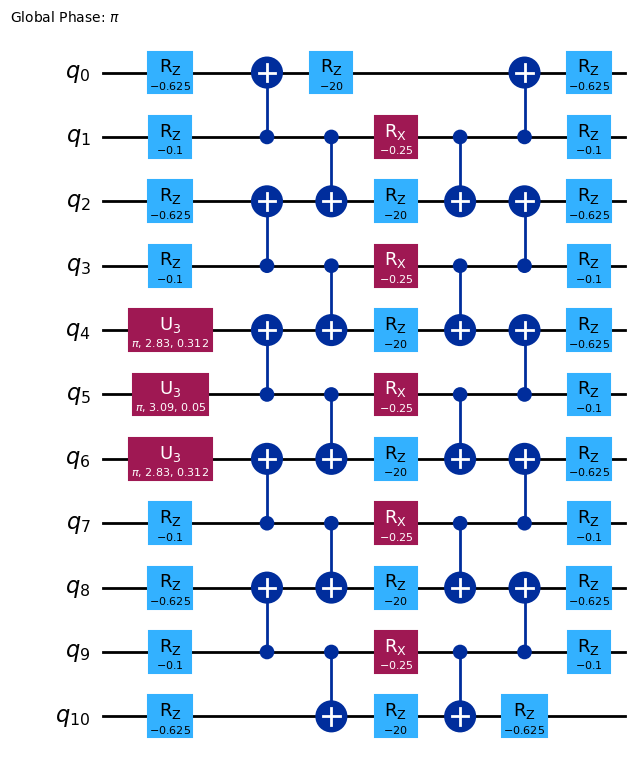

In [81]:
L = 6
J = 5
h = 0.8
lamb = 1
g = 10
x_basis = False

particle_pair_left_position = L//2 - 1 
particle_pair_length = 1

final_time = 5
layers = 40
measure_every_layers = 1

import z2chain.circs as circs

logical_non_cliff_circs = circs.particle_pair_quench_simulation_circuits(L, J, h, lamb, particle_pair_left_position, particle_pair_length, final_time, layers, g=g, measure_every_layers=measure_every_layers, x_basis=x_basis)
logical_non_cliff_circs[1].draw(output="mpl")

## 2. logical near-clifford circuits set at time $t$ 

In [82]:
t = 1
n = 20
N = 10
circ_t = logical_non_cliff_circs[t]
logical_near_cliff_set = near_clifford_circuits_set(circ_t, n=n, N=N)

Near-Clifford set has 18.87% of Non-clifford gates


## 3. MPS exacutions at time $t$

In [83]:
estimator_options = {
    "default_precision": 0
}

mps_simulator_options = {
    "method": "matrix_product_state",
    "matrix_product_state_max_bond_dimension": None,
    "matrix_product_state_truncation_threshold": 1e-16
}

observables_generating_funcs = [partial(local_pauli_z, qubit_ind=i) for i in range(2*L-1)]

mps_jobs_non_cliff_t = execute_simulation_estimator_batch(mps_simulator_options, estimator_options, circ_t, observables_generating_funcs)
mps_obs_non_cliff_t = convert_jobs_to_site_gauge_matrix(mps_jobs_non_cliff_t)

mps_jobs_near_cliff_t = execute_simulation_estimator_batch(mps_simulator_options, estimator_options, logical_near_cliff_set, observables_generating_funcs)
mps_obs_near_cliff_t = convert_jobs_to_site_gauge_matrix(mps_jobs_near_cliff_t)

## 4. Transpile, simulate, postselect at time $t$

In [84]:
# transpilation settings
optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
trotter_pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=simulator, initial_layout=layout)

# postselection settings
confidence = 0.7

odr = False
flip_threshold = None

observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

# postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
# to_remove_str = "I"*(2*L-3) + "ZZ"
# to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
# flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
# flipped_syndromes[to_remove_str_ind] = 1
flipped_syndromes = None

# -------------------------
# non-clifford
# -------------------------
# transpilation at time t
circ_t.measure_all()
physical_non_cliff_circ_t = trotter_pm.run(circ_t)

# simulation at time t
shots_non_cliff = 16000
print("Run simulation")
samples_dicts_non_cliff_t = simulator.run(physical_non_cliff_circ_t, shots=shots_non_cliff).result().get_counts()

# postselection at time t
print("\nPostselect samples dicts")
postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_non_cliff_t, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
# postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_non_cliff_t, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=bias_corrected_get_recovered_samples_dicts)
sim_obs_non_cliff_t, sim_conf_non_cliff_t = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
raw_obs_non_cliff_t, raw_conf_non_cliff_t = multiprocess_measure_diagonal_observables(np.array(samples_dicts_non_cliff_t), diagonal_observables, 0 if confidence is None else confidence)

# postselected_samples_dicts = get_recovered_postselected_samples_dict(samples_dicts_non_cliff_t, postselection_ops, flip_threshold)
# sim_obs_non_cliff_t, sim_conf_non_cliff_t = measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, confidence=confidence)
# raw_obs_non_cliff_t, raw_conf_non_cliff_t = measure_diagonal_observables(samples_dicts_non_cliff_t, diagonal_observables, confidence=confidence)

sim_obs_non_cliff_t = np.array(sim_obs_non_cliff_t)
sim_obs_non_cliff_t = (1 - sim_obs_non_cliff_t)/2
sim_conf_non_cliff_t = np.array(sim_conf_non_cliff_t)
raw_obs_non_cliff_t = np.array(raw_obs_non_cliff_t)
raw_obs_non_cliff_t = (1 - raw_obs_non_cliff_t)/2
raw_conf_non_cliff_t = np.array(raw_conf_non_cliff_t)


# -------------------------
# near-clifford
# -------------------------
# transpilation at time t
[nc_circ.measure_all() for nc_circ in logical_near_cliff_set]
physical_circs = trotter_pm.run(logical_near_cliff_set)

# simulation at time t
shots_near_cliff = 8000
samples_dicts_near_cliff_t = []
print("Run simulation")
for i in range(len(physical_circs)):
    print(f"\ri = {i}", end="")
    this_samples_dict = simulator.run(physical_circs[i], shots=shots_near_cliff).result().get_counts()
    samples_dicts_near_cliff_t.append(this_samples_dict)

# postselection at time t
sim_obs_near_cliff_t, sim_conf_near_cliff_t = [], []
raw_obs_near_cliff_t, raw_conf_near_cliff_t = [], []
print("\nPostselect samples dicts")
for i in range(len(samples_dicts_near_cliff_t)):
    print(f"\ri = {i}", end="")
    postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_near_cliff_t[i], postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
    # postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts_near_cliff_t[i], postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=bias_corrected_get_recovered_samples_dicts)
    sim_observables, sim_observables_confidence = multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, 0 if confidence is None else confidence)
    raw_observables, raw_observables_confidence = multiprocess_measure_diagonal_observables(np.array(samples_dicts_near_cliff_t[i]), diagonal_observables, 0 if confidence is None else confidence)

    # postselected_samples_dicts = get_recovered_postselected_samples_dict(samples_dicts_near_cliff_t[i], postselection_ops, flip_threshold)
    # sim_observables, sim_observables_confidence = measure_diagonal_observables(postselected_samples_dicts, diagonal_observables, confidence=confidence)
    # raw_observables, raw_observables_confidence = measure_diagonal_observables(samples_dicts_near_cliff_t[i], diagonal_observables, confidence=confidence)
    sim_obs_near_cliff_t.append(sim_observables)
    sim_conf_near_cliff_t.append(sim_observables_confidence)
    raw_obs_near_cliff_t.append(raw_observables)
    raw_conf_near_cliff_t.append(raw_observables_confidence)

sim_obs_near_cliff_t = np.array(sim_obs_near_cliff_t)
sim_obs_near_cliff_t = (1 - sim_obs_near_cliff_t)/2
sim_conf_near_cliff_t = np.array(sim_conf_near_cliff_t)
raw_obs_near_cliff_t = np.array(raw_obs_near_cliff_t)
raw_obs_near_cliff_t = (1 - raw_obs_near_cliff_t)/2
raw_conf_near_cliff_t = np.array(raw_conf_near_cliff_t)


Run simulation

Postselect samples dicts
Run simulation
i = 19
Postselect samples dicts
i = 19

In [85]:
sim_obs_non_cliff_t.shape, mps_obs_near_cliff_t.shape, sim_obs_near_cliff_t.shape

((11,), (20, 11), (20, 11))

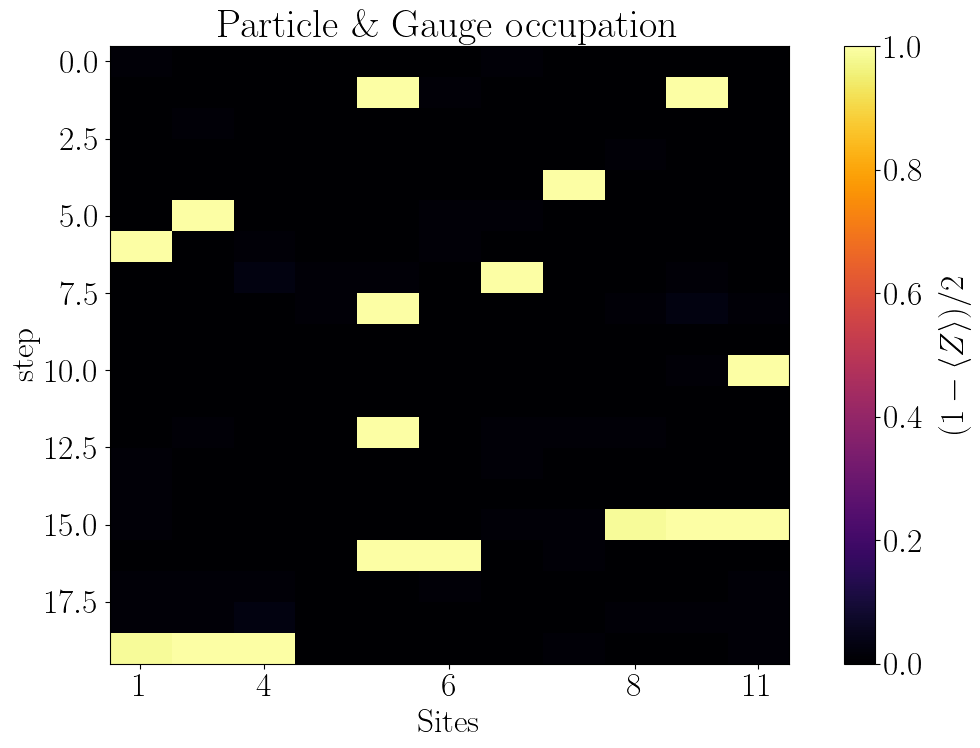

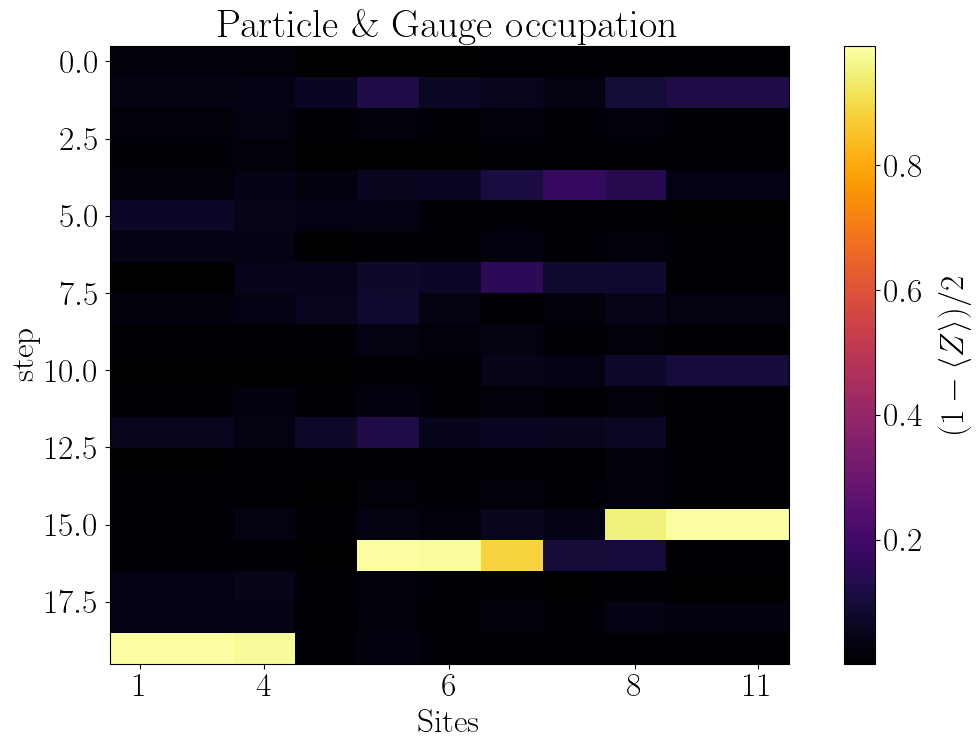

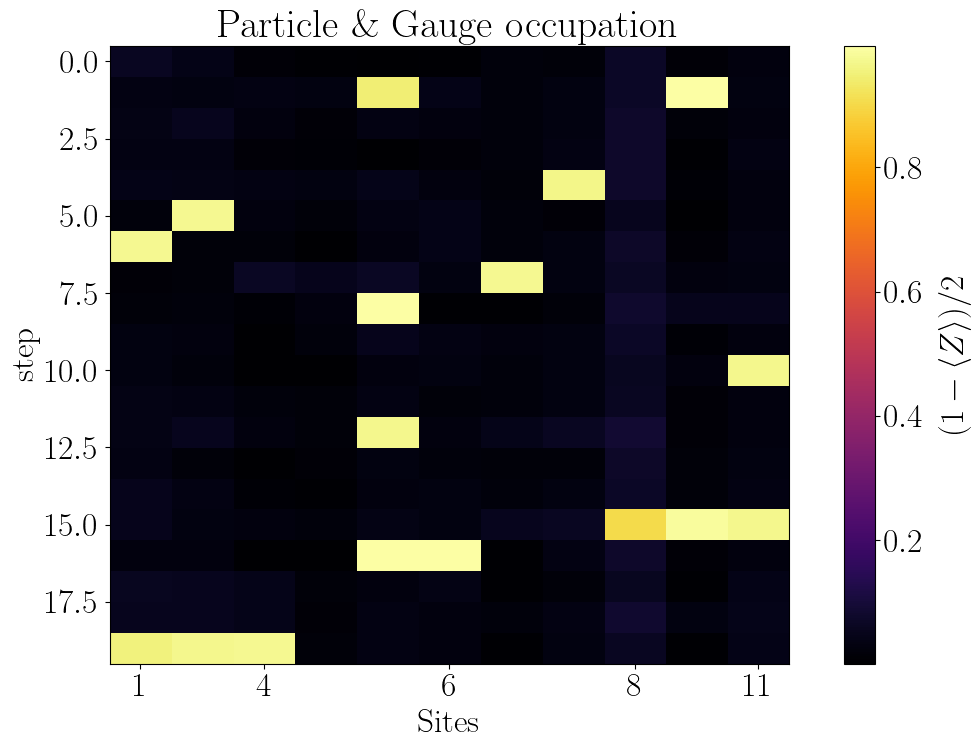

(array([0.01554379, 0.01554379, 0.03060436, 0.01554379, 0.96939564,
        0.98445621, 0.96939564, 0.01554379, 0.03060436, 0.01554379,
        0.01554379]),
 array([0.0315625, 0.0315625, 0.06475  , 0.0369375, 0.9340625, 0.96675  ,
        0.941    , 0.0315   , 0.0521875, 0.0235625, 0.0235625]))

In [86]:
x_t_plot(mps_obs_near_cliff_t)
x_t_plot(sim_obs_near_cliff_t)
x_t_plot(raw_obs_near_cliff_t)
mps_obs_non_cliff_t[0], sim_obs_non_cliff_t

## 5. Data Regression at time $t$

In [90]:
corrected_obs, corrected_obs_err = cdr_observables_t(L=L, exact_near_cliff_obs=mps_obs_near_cliff_t, noisy_near_cliff_obs=sim_obs_near_cliff_t, noisy_non_cliff_obs=sim_obs_non_cliff_t.reshape((1,2*L-1)), t=0)

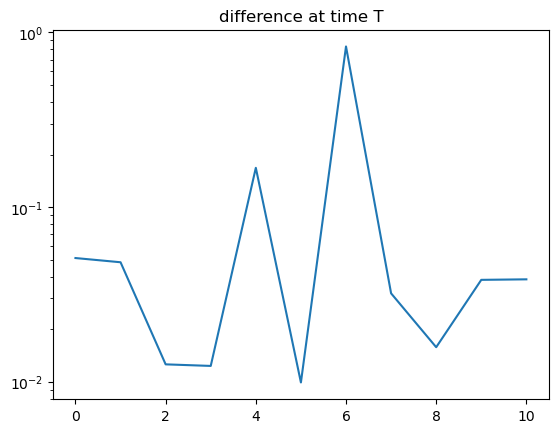

In [91]:
plt.title("difference at time T")
plt.plot(range(2*L-1), np.abs(corrected_obs - mps_obs_non_cliff_t)[0])
plt.yscale('log')

# Automatize the Pipeline

### iteration over time

In [93]:
def clifford_data_regression(logical_non_cliff_circs, n: list, N: list, shots_non_cliff: list, shots_near_cliff: list):
    corrected_obs = []
    corrected_obs_err = []
    mps_obs_non_cliff = []
    sim_obs_non_cliff = []
    for t in range(len(logical_non_cliff_circs)-1):
        print(f"\r clifford data regression at time step: {t}", end="")
        print("\n")

        # 2. create set
        circ_t = logical_non_cliff_circs[t+1]
        logical_near_cliff_set = near_clifford_circuits_set(circ_t, n=n[t], N=N[t])

        # 3. execute mps
        mps_obs_non_cliff_t, mps_obs_near_cliff_t = execute_mps_t(circ_t, logical_near_cliff_set)
        mps_obs_non_cliff.append(mps_obs_non_cliff_t)
        
        # 4.1 transpilation, noisy simulation, postselection -- non-clifford 
        (sim_obs_non_cliff_t,
        sim_conf_non_cliff_t,
        raw_obs_non_cliff_t,
        raw_conf_non_cliff_t) = transpile_simulate_postselect_non_clifford(circ_t, L, backend, simulator, shots_non_cliff[t])
        sim_obs_non_cliff.append(sim_obs_non_cliff_t)
        
        # 4.2 transpilation, noisy simulation, postselection -- near-clifford
        # transpilation at time t
        (sim_obs_near_cliff_t,
        sim_conf_near_cliff_t,
        raw_obs_near_cliff_t,
        raw_conf_near_cliff_t) = transpile_simulate_postselect_near_clifford(logical_near_cliff_set, L, backend, simulator, shots_near_cliff[t])

        # 5. correct with data regression
        corrected_obs_t, corrected_obs_err_t = cdr_observables_t(L=L, exact_near_cliff_obs=mps_obs_near_cliff_t, noisy_near_cliff_obs=sim_obs_near_cliff_t, noisy_non_cliff_obs=sim_obs_non_cliff_t.reshape((1,2*L-1)), t=0)
        corrected_obs.append(corrected_obs_t)
        corrected_obs_err.append(corrected_obs_err_t)
        
    return corrected_obs, corrected_obs_err, mps_obs_non_cliff, sim_obs_non_cliff

In [94]:
L = 6
J = 5
h = 0.8
lamb = 1
g = 10
x_basis = False

particle_pair_left_position = L//2 - 1 
particle_pair_length = 1

# final_time = 5
# layers = 40

layers = 3
final_time = 0.125*layers
measure_every_layers = 1

# we use uniform sets along time but can be changed if needed by specifing the wanted value at time t
n = [20]*(layers)
N = [10]*(layers)
shots_near_cliff = [8000]*(layers)
shots_non_cliff = [16000]*(layers)

logical_non_cliff_circs = circs.particle_pair_quench_simulation_circuits(L, J, h, lamb, particle_pair_left_position, particle_pair_length, final_time, layers, g=g, measure_every_layers=measure_every_layers, x_basis=x_basis)
corrected_obs, corrected_obs_err, mps_obs_non_cliff, sim_obs_non_cliff = clifford_data_regression(logical_non_cliff_circs, n=n, N=N, shots_non_cliff=shots_non_cliff, shots_near_cliff=shots_near_cliff)

 clifford data regression at time step: 0

Near-Clifford set has 18.87% of Non-clifford gates
 clifford data regression at time step: 1

Near-Clifford set has 10.53% of Non-clifford gates
 clifford data regression at time step: 2

Near-Clifford set has 7.30% of Non-clifford gates
 -- simulation near clifford = 19

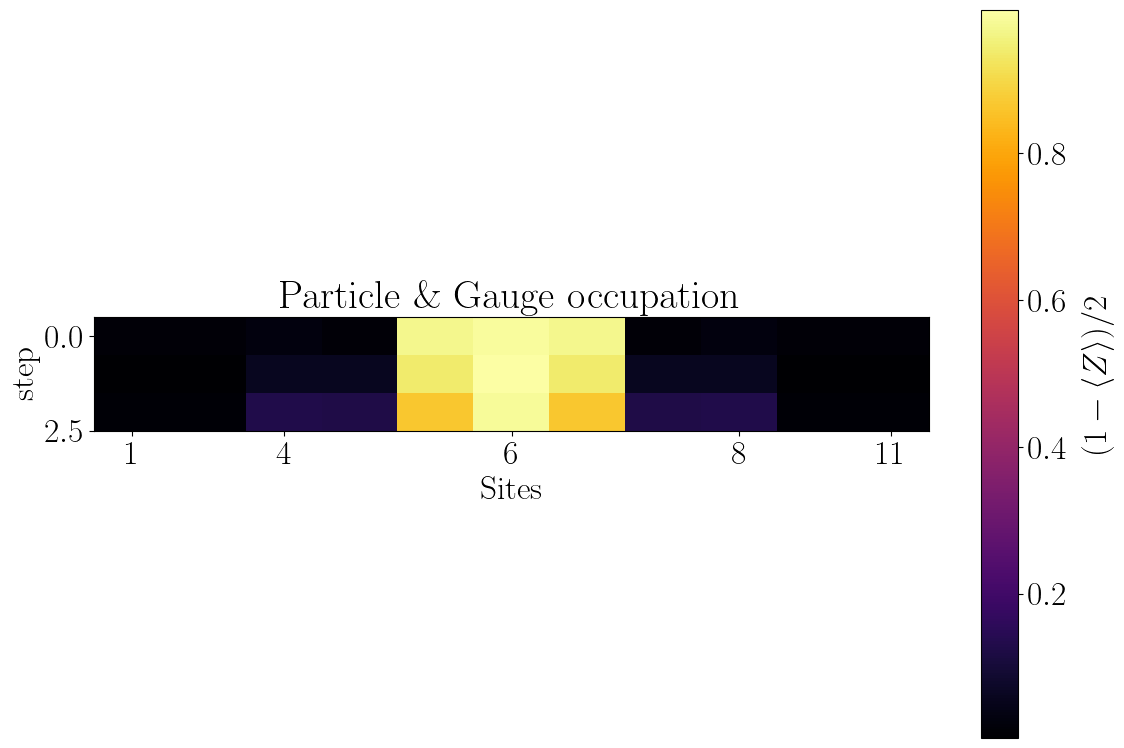

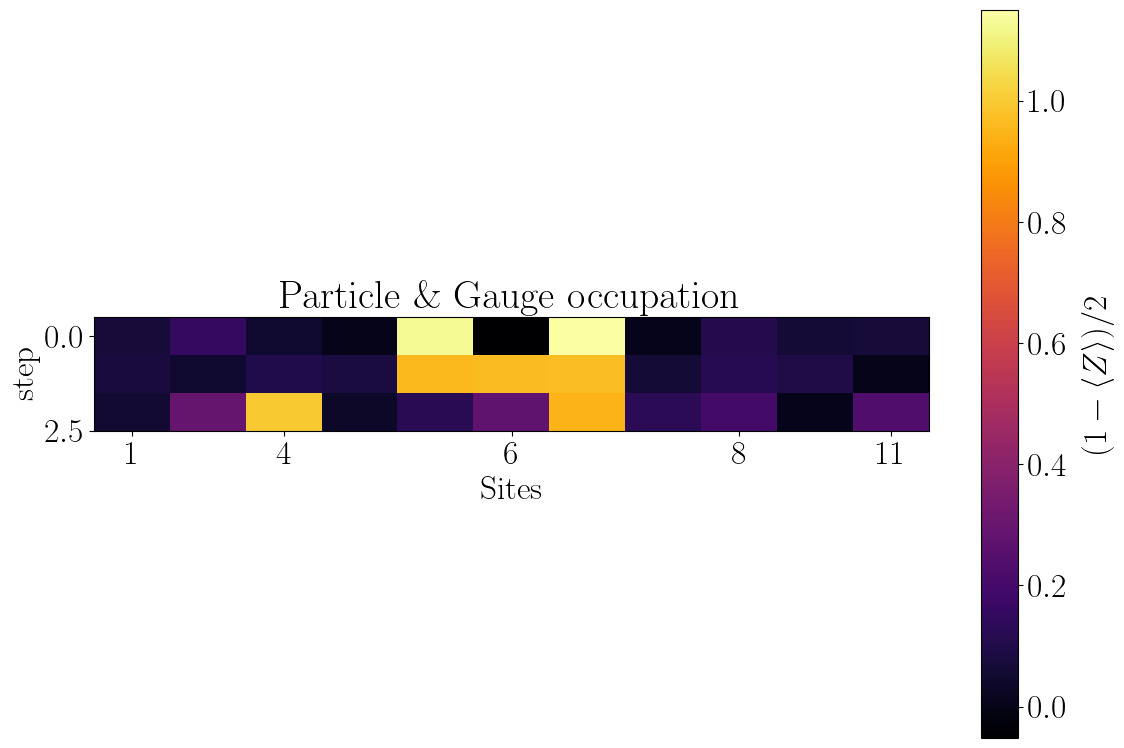

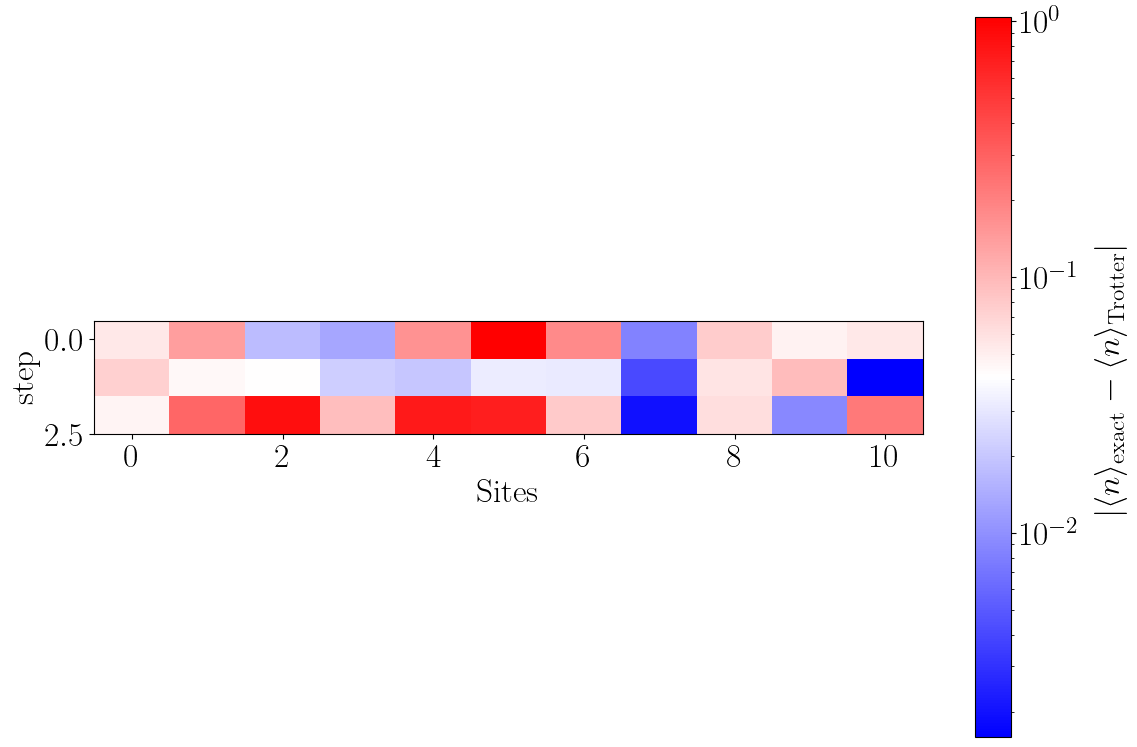

In [95]:
x_t_plot(np.asarray(mps_obs_non_cliff)[:,0,:])
x_t_plot(np.asarray(corrected_obs))
discrepancies_plot(np.asarray(mps_obs_non_cliff)[:,0,:], np.asarray(corrected_obs))